# 🎓 第2课：学术起源 —— 三位诺奖与「因子动物园」

**本节目标**：了解因子研究从哪来、现在有多乱（重要！），并亲手模拟「数据窥探」如何造假因子。

> 对应原书：第1章 1.2 节

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
def _find_sample():
    for p in [Path('data/sample'), Path.cwd().parents[2] / 'data' / 'sample']:
        if p.exists():
            return p
    raise FileNotFoundError('找不到 data/sample，请从仓库根目录启动 notebook')
SAMPLE = _find_sample()
plt.rcParams['figure.dpi'] = 110
print('✅ 环境就绪，开始学习！')

✅ 环境就绪，开始学习！


## ① 时间线（故事版）📜

- **1934** Graham & Dodd《证券分析》——「便宜股」思想的源头；
- **1960s** CAPM 问世——第一次用公式刻画风险-收益；
- **1976** APT（Ross）——从 1 个因子推广到多个；
- **1977/1981** 便宜股效应、小市值效应被发现——CAPM **解释不了**它们（异象！）；
- **1993** Fama-French 三因子模型——把两个异象「收编」成 SMB 和 HML 因子。

**规律**：异象倒逼模型升级 → 模型把异象收编成因子 → 新异象出现 → ……

## ② 三位诺奖大师 🏆（2013 年共享诺奖）

- **Fama（有效市场之父）**：① 联合假说（1970）——**想检验市场有没有效，先得有把对的尺子（定价模型）**；
  ② Fama-MacBeth 回归（1973）——检验模型的统计工具；③ FF 三因子模型（1993）。
- **Hansen**：发明 GMM（1982）——检验模型的「万能账本」（第2章详讲）。
- **Shiller（行为金融）**：噪音交易者模型（1984）——价格涨过头跌过头，因为人非理性。

> 🧠 注意 Fama 和 Shiller 立场相反：Fama 认为市场有效，Shiller 认为市场常犯错——
> **因子投资就诞生在这两种立场的拉扯中**：有效市场需要因子（风险补偿），
> 行为金融需要异象（错误定价）。

## ③ 案例1：「数据窥探」模拟 —— 随机数里挖假因子 🎲

数据窥探 = **先看数据、再编故事**（先射箭、再画靶）。
模拟一下：生成 **1000 个纯随机噪声序列**（市场里根本不存在任何因子），
然后用「|t|>2 就算显著」的标准去挖——能挖出多少个「显著因子」？

纯噪声序列中，|t|>2 的「显著因子」: 42 个 / 1000 (4.2%)


C:\Users\Admin\AppData\Local\Temp\ipykernel_7212\364125379.py:13: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  plt.legend(); plt.tight_layout(); plt.show()
C:\Users\Admin\AppData\Local\Temp\ipykernel_7212\364125379.py:13: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.legend(); plt.tight_layout(); plt.show()
C:\Users\Admin\AppData\Local\Temp\ipykernel_7212\364125379.py:13: UserWarning: Glyph 37327 (\N{CJK UNIFIED IDEOGRAPH-91CF}) missing from font(s) DejaVu Sans.
  plt.legend(); plt.tight_layout(); plt.show()
C:\Users\Admin\AppData\Local\Temp\ipykernel_7212\364125379.py:13: UserWarning: Glyph 20010 (\N{CJK UNIFIED IDEOGRAPH-4E2A}) missing from font(s) DejaVu Sans.
  plt.legend(); plt.tight_layout(); plt.show()
C:\Users\Admin\AppData\Local\Temp\ipykernel_7212\364125379.py:13: UserWarning: Glyph 22122 (\N{CJK UNIFIED IDEOGRAPH-566A}) missing from font(s) DejaVu Sans.
  plt.legend(); plt.ti

C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 37327 (\N{CJK UNIFIED IDEOGRAPH-91CF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20010 (\N{CJK UNIFIED IDEOGRAPH-4E2A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 22122 (\N{CJK UNIFIED IDEOGRAPH-566A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Local\Programs\Python

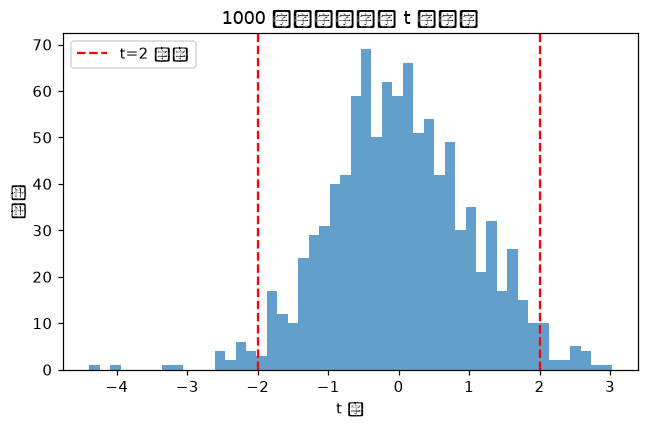

In [2]:
rng = np.random.default_rng(2020)
n_trials, T = 1000, 120
trials = rng.normal(0, 0.02, size=(n_trials, T))   # 纯噪声！
ts = trials.mean(axis=1) / (trials.std(axis=1) / np.sqrt(T))
sig = np.abs(ts) > 2
print(f'纯噪声序列中，|t|>2 的「显著因子」: {sig.sum()} 个 / {n_trials} ({sig.mean()*100:.1f}%)')

plt.figure(figsize=(6, 4))
plt.hist(ts, bins=50, alpha=0.7)
plt.axvline(2, color='red', ls='--', label='t=2 阈值')
plt.axvline(-2, color='red', ls='--')
plt.xlabel('t 值'); plt.ylabel('数量'); plt.title('1000 个噪声序列的 t 值分布')
plt.legend(); plt.tight_layout(); plt.show()

## ④ 「因子动物园」警告 ⚠️（记住三个数字）

| 事实 | 出处 |
|---|---|
| 学术界已挖出 **400+** 个因子，多数是数据窥探的产物 | Cochrane (2011) |
| 显著性门槛从 t=2.0 抬到 **3.0** | Harvey et al. (2016) |
| 再抬到 **3.4**；因子发表后收益平均**衰减 50%+** | Chordia (2020)、McLean & Pontiff (2016) |

> 🍜 衰减 = **网红店红了就排队，利润被摊薄**：越多人知道的因子越不赚钱。

## ⑤ 案例2：「发表后衰减」模拟 📉

研究者会挑「表现最好的区间」发表（另一种数据窥探）——模拟这个过程看衰减多少：

In [3]:
rng = np.random.default_rng(7)
T = 240
true_premium = 0.004  # 真实月均溢价 0.4%
ret = rng.normal(true_premium, 0.03, size=T)

# 「发表前」：挑 60 个月里表现最好的区间（数据窥探）
best = max(range(0, T - 60), key=lambda s: ret[s:s+60].mean())
in_sample = ret[best:best+60].mean()
# 「发表后」：全部 240 个月的真相
out_sample = ret.mean()
print(f'发表前（挑最优区间）月均: {in_sample*100:.2f}%')
print(f'发表后（长期真相）月均:   {out_sample*100:.2f}%')
print(f'衰减幅度: {100*(1 - out_sample/in_sample):.0f}%（真实世界中 McLean-Pontiff 测得 ~50%+）')

发表前（挑最优区间）月均: 0.58%
发表后（长期真相）月均:   -0.05%
衰减幅度: 108%（真实世界中 McLean-Pontiff 测得 ~50%+）


## ✋ 试一试

1. 把案例1的阈值改成 t=3.0 重跑——「显著因子」从 5% 降到多少？这就是 Harvey 抬高门槛的意义。
2. 案例2里把 `best` 窗口从 60 个月改成 12 个月——衰减更严重还是更轻？为什么？

## ✅ 小结

- 因子研究=异象倒逼模型升级的循环；Fama/Hansen/Shiller 三人奠定了全部工具；
- **数据窥探**让 400+ 因子大半不可信——读论文先问：**这个因子在样本外还活着吗？**

> 下一课：业界全景——管理人怎么用因子、投资者怎么买因子。